In [1]:
%pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\taesp\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['savefig.transparent'] = False

In [3]:
df = pd.read_json('../tweets.jsonl', lines=True, nrows=100_000)
df.head()

,tid,author_id,author_screen_name,tweet_text,lang,datetime,location,t_location
0,1402998346705367054,1093143512416165889,KothariManjeet,@ANI Some virus in the program!!!,en,2021-06-10 14:37:26+00:00,"Ahmadabad City, India",NaN
1,1476139752084496385,1393054099365457921,AnilPil63050188,"RT @total_woke_: Mughals were refugees, Brahmi...",en,2021-12-29 10:35:16+00:00,INDIA,NaN
2,1382919154269884416,135934253,maxfoods,Just posted a photo @ Farmer's Kitchen https:/...,en,2021-04-16 04:49:54+00:00,New Delhi,"Gurgaon, India"
3,1478369103895097345,1151789276159307778,ThuppakiDaw_,RT @TFC_mass: @ActorKartikeya We Are Sure You ...,en,2022-01-04 14:13:55+00:00,India,NaN
4,1442911531897741313,1243176186152394754,bankeronduty,RT @Paul_Oommen: Alleged #PawanKalyan fans tri...,en,2021-09-28 17:58:11+00:00,"Vijayawada, India",NaN


In [4]:
df.shape

(100000, 8)

In [5]:
df.dtypes

tid                                 int64
author_id                           int64
author_screen_name                    str
tweet_text                            str
lang                                  str
datetime              datetime64[us, UTC]
location                              str
t_location                            str
dtype: object

In [6]:
df.isnull().sum()

tid                       0
author_id                 0
author_screen_name        0
tweet_text                0
lang                      0
datetime                  0
location               4472
t_location            81066
dtype: int64

In [7]:
df.tid.duplicated().sum()

np.int64(0)

In [8]:
df.tweet_text.sample(10).to_list()

['RT @INCIndia: PM cares for PR and not people; first Varanasi, now Narmada, the horror that is unfolding in these districts is proof of it!…',
 'RT @jasminwriter95: Rone walon ko rone ka bahana chahiye par hamare paas kuch hone ki wajah hai ki just 2 days later we can see Teja once a…',
 'RT @RahulGandhi: Facebook US says Bajrang Dal content is offensive and should be banned.\n\nFacebook India tells our Parliamentary panel that…',
 '@FGLifeIndia 1- TRUST\n2-PREMIUM\n3-INSURANCE\n\n#BharosaPapaJaisa #FutureGeneraliIndiaLife #FGILI #Insurance #LifeInsurance',
 'RT @ANI: In view of COVID19 pandemic, the Election Commission of India decides to defer by-elections of Dadra &amp; Nagar Haveli, Khandwa (Madh…',
 'RT @ANI: Now a BJP-Shiv Sena govt has taken charge, based on the beliefs of Balasaheb Thackeray. Till date, we had seen that people change…',
 '@chartbent Might come down now ...',
 '@PMishra_Journo Press Freedom Index \n\nCanada 🇨🇦: 19\nIndia 🇮🇳: 150\n\nRecently Canada govt imposed 

In [9]:
t = df['tweet_text']
n = len(df)

In [10]:
(t.str.startswith('RT @')).mean()       # share of retweets

np.float64(0.60408)

In [11]:
t.str.contains('@', na=False).mean()    # mentions

np.float64(0.84616)

In [12]:
t.str.contains('#', na=False).mean()    # hashtags

np.float64(0.33649)

In [13]:
(t.str.count(r'#\w+') >= 2).mean()      # 2+ hashtags (needed for Task 2)

np.float64(0.14861)

In [14]:
df['lang'].value_counts().head(10)

lang
en    100000
Name: count, dtype: int64

In [15]:
df['datetime'] = pd.to_datetime(df['datetime'])
df['datetime'].min(), df['datetime'].max()

(Timestamp('2014-07-21 20:40:34+0000', tz='UTC'),
 Timestamp('2022-12-14 05:37:59+0000', tz='UTC'))

In [16]:
df['author_screen_name'].value_counts().head(10)

author_screen_name
htTweets           277
IndiaToday         219
ndtv               198
TimesNow           197
ANI                141
propertiesindia    112
flipkartsupport     94
dna                 81
ZeeNewsEnglish      75
the_hindu           74
Name: count, dtype: int64

## Extract @mentions
- usernames are lowercased (no self mentions)
- keep retweets

In [17]:
import re
import os
import networkx as nx
from collections import Counter

mention_pattern = re.compile(r'@(\w+)')

def extract_mentions(text):
    if not isinstance(text, str):
        return []
    return [m.lower() for m in mention_pattern.findall(text)]

### Build the edge list from the full dataset

Read the file in chunks of 500,000 lines and only keep the `(author, mentioned)` pair counts.
Result is saved to `edges.csv`.

In [18]:
EDGES_FILE = '../edges.csv'

if os.path.exists(EDGES_FILE):
    edges = pd.read_csv(EDGES_FILE, keep_default_na=False)
    print('Loaded edges from', EDGES_FILE)
else:
    edge_counts = Counter()
    seen_tids = set()
    total_tweets = 0

    reader = pd.read_json('../tweets.jsonl', lines=True, chunksize=500_000, dtype=False)
    for chunk in reader:
        chunk = chunk[['tid', 'author_screen_name', 'tweet_text']].dropna()
        total_tweets += len(chunk)

        # skip duplicates if any
        chunk = chunk[~chunk['tid'].isin(seen_tids)]
        seen_tids.update(chunk['tid'])

        # keep only tweets that have an @
        chunk = chunk[chunk['tweet_text'].str.contains('@')]

        for author, text in zip(chunk['author_screen_name'].str.lower(), chunk['tweet_text']):
            for mentioned in extract_mentions(text):
                if mentioned != author:
                    edge_counts[(author, mentioned)] += 1

        print('tweets read so far:', total_tweets)

    edges = pd.DataFrame(
        [(a, b, w) for (a, b), w in edge_counts.items()],
        columns=['source', 'target', 'weight'],
    )
    edges.to_csv(EDGES_FILE, index=False)
    print('Total tweets:', total_tweets, '| unique tweets:', len(seen_tids))
    del edge_counts, seen_tids   # free memory

print('Number of edges:', len(edges))
edges.sort_values('weight', ascending=False).head(10)

Loaded edges from edges.csv
Number of edges: 6884178


,source,target,weight
1509,ndtv,ndtvfeed,4418
679,nemityadav1,ani,3417
1172,kaushiknath96,ani,2400
616,timesnow,thenewshour,2042
6889,rkb97official,cmo_odisha,1924
6890,rkb97official,secychief,1922
6892,rkb97official,mosarkar5t,1922
6891,rkb97official,gapg_dept,1920
4263,kjayeshb,pmoindia,1803
222,mohitsmartlove,timesofindia,1795


## Build the directed mention graph

In [19]:
G = nx.DiGraph()
G.add_weighted_edges_from(edges[['source', 'target', 'weight']].itertuples(index=False))

print('Nodes:', G.number_of_nodes())
print('Edges:', G.number_of_edges())

Nodes: 1951994
Edges: 6884178


In [20]:
# how many users are mentioned vs. only mention others
in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())
print('Users who are mentioned at least once:', sum(1 for d in in_deg.values() if d > 0))
print('Users who do not get mentioned', sum(1 for n in G if in_deg[n] == 0))

Users who are mentioned at least once: 1039516
Users who do not get mentioned 912478


## Centrality

1. **In-degree centrality**: how many different users mention you (popularity).
2. **Out-degree centrality**: how many different users you mention (activity, _not_ influence).
3. **PageRank**: you are important if important users mention you.
4. **Betweenness centrality**: how often you sit on shortest paths between other users.

In [21]:
in_degree_c = nx.in_degree_centrality(G)
out_degree_c = nx.out_degree_centrality(G)
print('degree centrality done')

pagerank = nx.pagerank(G, alpha=0.85, weight='weight')
print('pagerank done')

degree centrality done
pagerank done


### Betweenness (approximate)

Exact betweenness is $O(V\cdot E)$: far too slow maybe.
So we:
1. take the **core** of the graph: the top 20,000 users by total degree, and
2. use **k = 300 sampled source nodes** instead of all nodes (`nx.betweenness_centrality(k=...)`).

In [22]:
CORE_SIZE = 20_000
total_deg = dict(G.degree())
core_nodes = sorted(total_deg, key=total_deg.get, reverse=True)[:CORE_SIZE]
G_core = G.subgraph(core_nodes)
print('Core graph:', G_core.number_of_nodes(), 'nodes,', G_core.number_of_edges(), 'edges')

betweenness = nx.betweenness_centrality(G_core, k=300, seed=42)
print('betweenness done')

Core graph: 20000 nodes, 798957 edges
betweenness done


## Top influencers

In [23]:
scores = pd.DataFrame({
    'in_degree': pd.Series(in_degree_c),
    'out_degree': pd.Series(out_degree_c),
    'pagerank': pd.Series(pagerank),
    'betweenness': pd.Series(betweenness),   # NaN for users outside the core
})
scores['betweenness'] = scores['betweenness'].fillna(0)
scores.index.name = 'user'
scores.head()

,in_degree,out_degree,pagerank,betweenness
user,,,,
0,7.172157e-06,0.000000e+00,1.071426e-06,0.0
00,5.122969e-07,0.000000e+00,3.146276e-07,0.0
00000000001234z,0.000000e+00,5.635266e-06,2.710824e-07,0.0
0000000000nikki,0.000000e+00,5.122969e-06,2.710824e-07,0.0
0000000000one,1.024594e-06,5.122969e-07,2.962947e-07,0.0


In [24]:
TOP = 15
for col in ['in_degree', 'pagerank', 'betweenness', 'out_degree']:
    print(f'--- Top {TOP} by {col} ---')
    print(scores[col].sort_values(ascending=False).head(TOP).to_string())
    print()

--- Top 15 by in_degree ---
user
narendramodi      0.076617
ani               0.045229
rahulgandhi       0.030927
pmoindia          0.028579
ndtv              0.019845
amitshah          0.017992
incindia          0.017271
bjp4india         0.016022
arvindkejriwal    0.015347
swamy39           0.012053
timesnow          0.011342
indiatoday        0.011225
shashitharoor     0.010765
timesofindia      0.010487
himantabiswa      0.009642

--- Top 15 by pagerank ---
user
narendramodi       0.025217
ani                0.013605
rahulgandhi        0.009425
ndtv               0.004885
pmoindia           0.004646
incindia           0.003922
arvindkejriwal     0.003691
swamy39            0.002955
amitshah           0.002463
timesofindia       0.002344
shashitharoor      0.002291
bjp4india          0.002234
himantabiswa       0.002218
timesnow           0.001847
myogiadityanath    0.001813

--- Top 15 by betweenness ---
user
indiatoday       0.082357
timesnow         0.053533
narendramodi     0.02

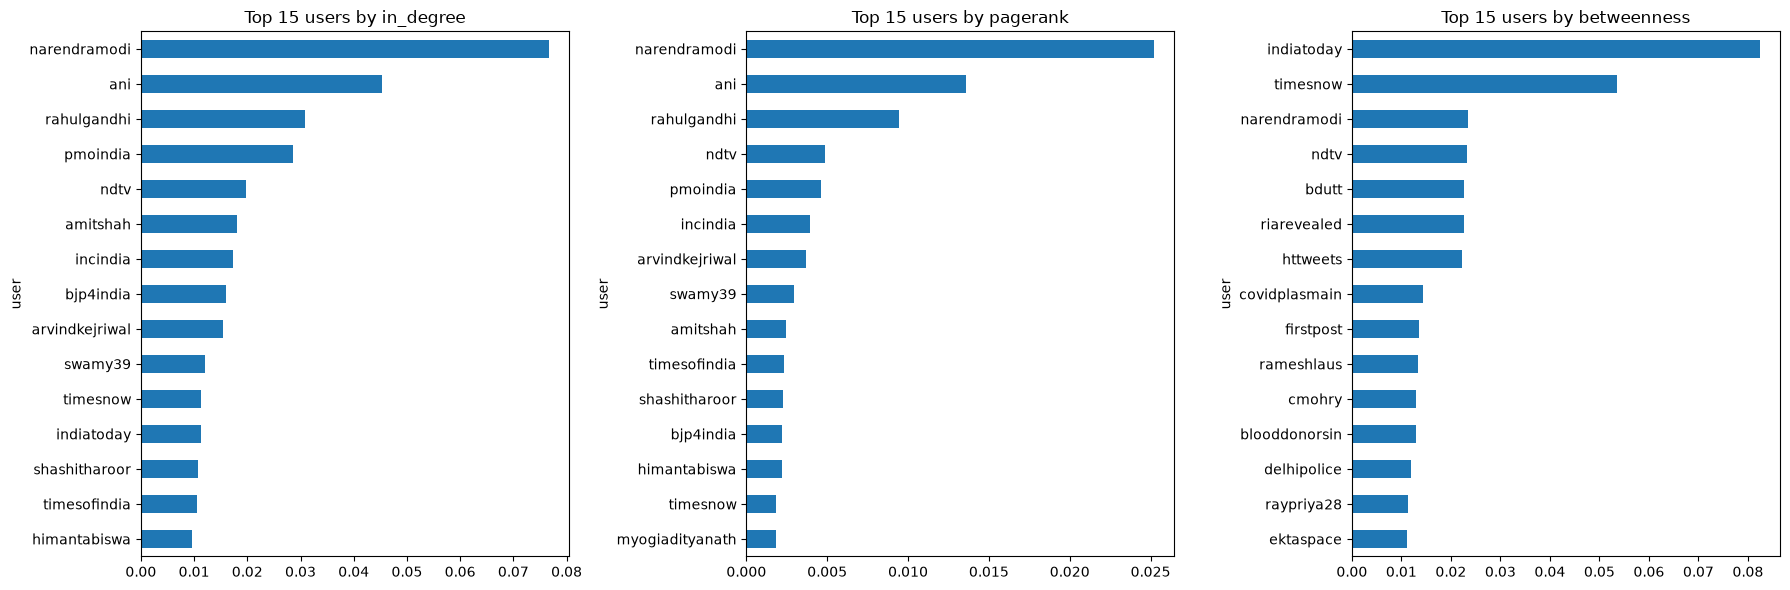

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, col in zip(axes, ['in_degree', 'pagerank', 'betweenness']):
    top = scores[col].sort_values(ascending=False).head(TOP)
    top[::-1].plot(kind='barh', ax=ax)
    ax.set_title(f'Top {TOP} users by {col}')
plt.tight_layout()
plt.savefig('top_influencers.svg', dpi=150)
plt.show()

### Do the measures agree?

- **Overlap**: how many users appear in the top 15 of two measures.
- **Spearman correlation**: correlation computed on the core users so betweenness is meaningful

In [26]:
top_sets = {col: set(scores[col].sort_values(ascending=False).head(TOP).index)
            for col in ['in_degree', 'pagerank', 'betweenness']}

print('in_degree & pagerank   :', len(top_sets['in_degree'] & top_sets['pagerank']))
print('in_degree & betweenness:', len(top_sets['in_degree'] & top_sets['betweenness']))
print('pagerank & betweenness :', len(top_sets['pagerank'] & top_sets['betweenness']))

in_degree & pagerank   : 14
in_degree & betweenness: 4
pagerank & betweenness : 3


In [27]:
scores.loc[core_nodes, ['in_degree', 'out_degree', 'pagerank', 'betweenness']].corr(method='spearman')

,in_degree,out_degree,pagerank,betweenness
in_degree,1.000000,-0.705911,0.954709,0.198779
out_degree,-0.705911,1.000000,-0.713883,0.272952
pagerank,0.954709,-0.713883,1.000000,0.158545
betweenness,0.198779,0.272952,0.158545,1.000000


## Export for Neo4j

The full graph is too big to view in Neo4j, so we export a smaller subgraph:
the **top 300 users by PageRank** and the edges between them.

In [28]:
NEO_TOP = 300
neo_nodes = scores.sort_values('pagerank', ascending=False).head(NEO_TOP)
neo_users = set(neo_nodes.index)

neo_edges = edges[edges['source'].isin(neo_users) & edges['target'].isin(neo_users)]

neo_nodes.reset_index().to_csv('neo4j_nodes.csv', index=False)
neo_edges.to_csv('neo4j_edges.csv', index=False)
print(len(neo_nodes), 'nodes and', len(neo_edges), 'edges exported')

300 nodes and 2011 edges exported


### Visualize Neo4j

The following codes were used for visualizing information in the Neo4j browser:
```cypher
// top 50 by PageRank and their mention links
MATCH (u:User) WITH u ORDER BY u.pagerank DESC LIMIT 50
MATCH (u)-[r:MENTIONS]-(v:User)
RETURN u, r, v;

// table of top 15 influencers (top15-pagerank.csv)
MATCH (u:User)
RETURN u.user AS user, round(u.pagerank, 5) AS pagerank,
       round(u.in_degree, 4) AS in_degree, round(u.betweenness, 4) AS betweenness
ORDER BY pagerank DESC LIMIT 15;
```

## network figures

drawn with networkX:
- only the **top 40 users by PageRank** and the edges between them
- **node size** = the centrality measure, **colour** = same measure, **edge width** = number of mentions

In [42]:
def draw_top_network(measure, n_top=40, filename=None):
    top_users = scores[measure].sort_values(ascending=False).head(n_top).index
    H = G.subgraph(top_users)

    # node size: take square root for not too bigging
    values = [scores.loc[u, measure] for u in H.nodes()]
    max_v = max(values)
    sizes = [200 + 2500 * np.sqrt(v / max_v) for v in values]

    # edge width: log scale
    weights = [H[a][b]['weight'] for a, b in H.edges()]
    max_w = max(weights)
    widths = [0.4 + 2.5 * np.log1p(w) / np.log1p(max_w) for w in weights]

    pos = nx.kamada_kawai_layout(H.to_undirected(), weight=None)

    fig, ax = plt.subplots(figsize=(16, 13))
    nx.draw_networkx_edges(H, pos, ax=ax, width=widths, alpha=0.25,
                           edge_color='grey', arrows=True, arrowsize=10,
                           node_size=sizes, connectionstyle='arc3,rad=0.1')
    nodes = nx.draw_networkx_nodes(H, pos, ax=ax, node_size=sizes, node_color=values,
                                   cmap='viridis', alpha=0.9, edgecolors='black', linewidths=0.5)

    label_pos = {u: (x, y - 0.045) for u, (x, y) in pos.items()}
    nx.draw_networkx_labels(H, label_pos, ax=ax, font_size=9,
                            bbox=dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1))

    plt.colorbar(nodes, ax=ax, label=measure, shrink=0.6)
    ax.set_title(f'Top {n_top} users in the mention network (sized and coloured by {measure})', fontsize=16)
    ax.axis('off')
    ax.margins(0.08)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

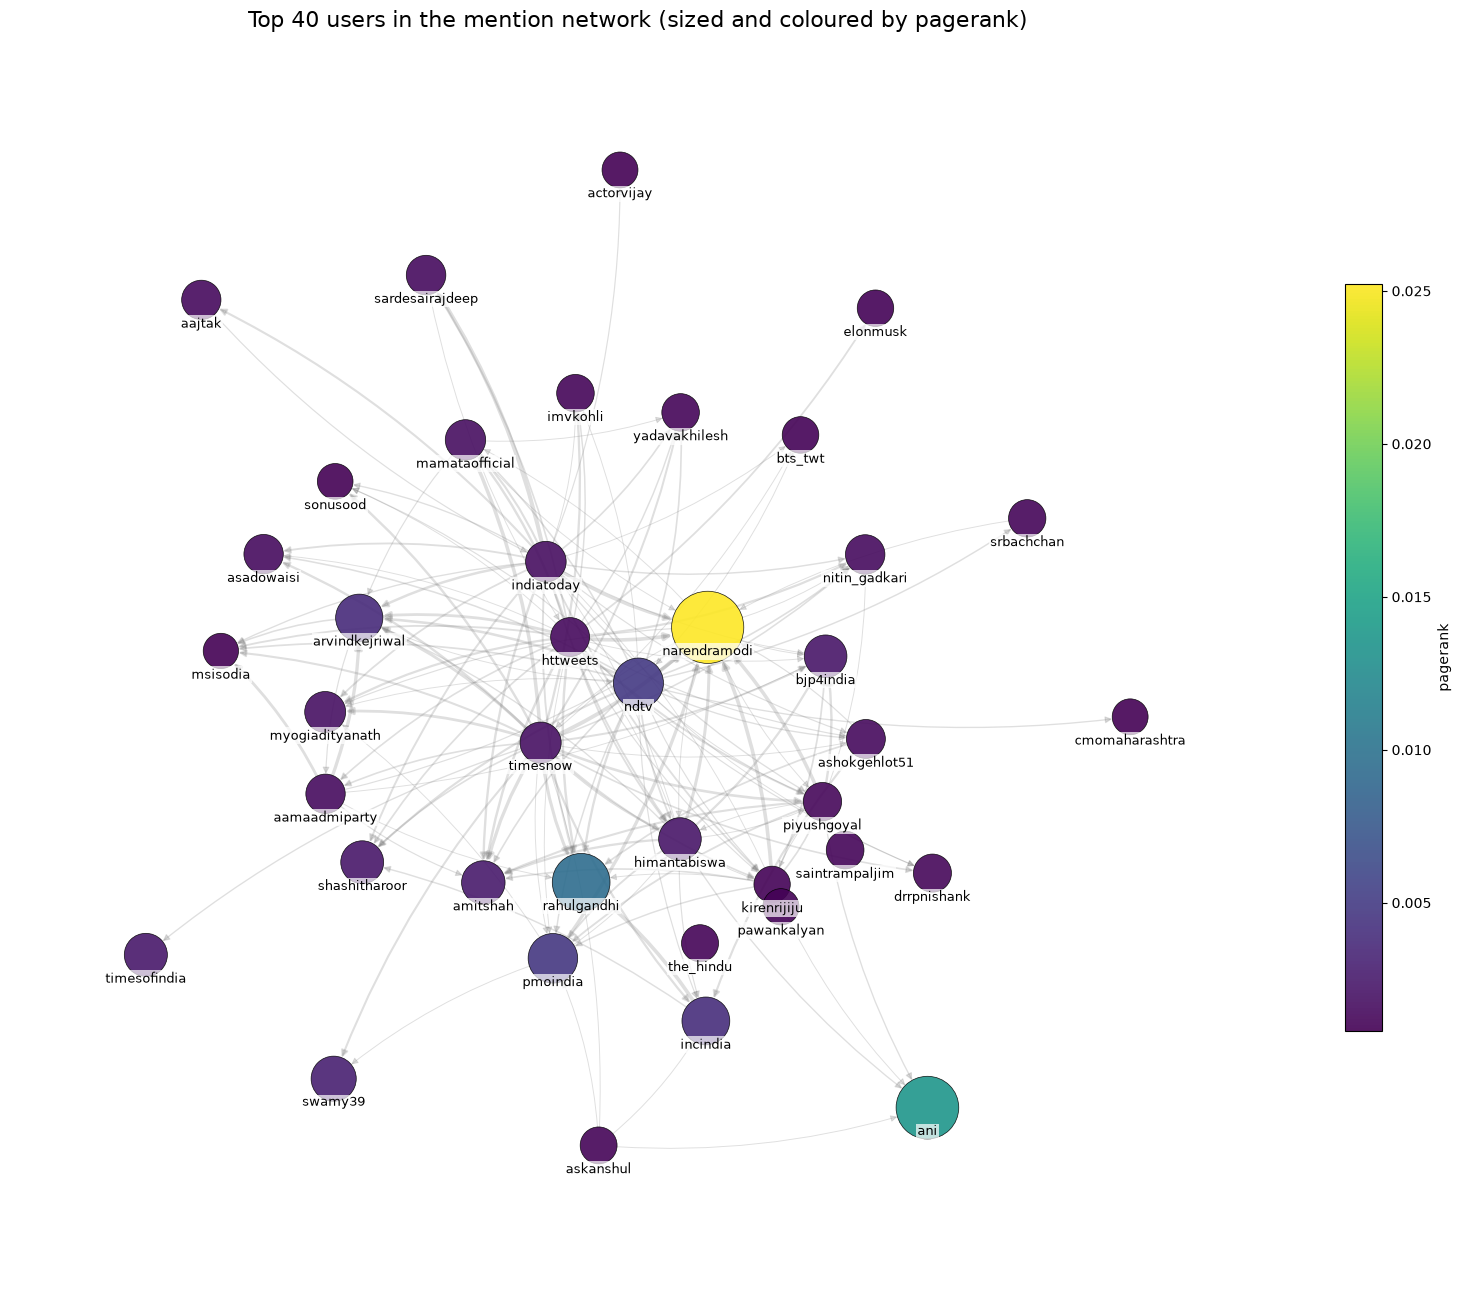

In [43]:
draw_top_network('pagerank', filename='network_pagerank.svg')

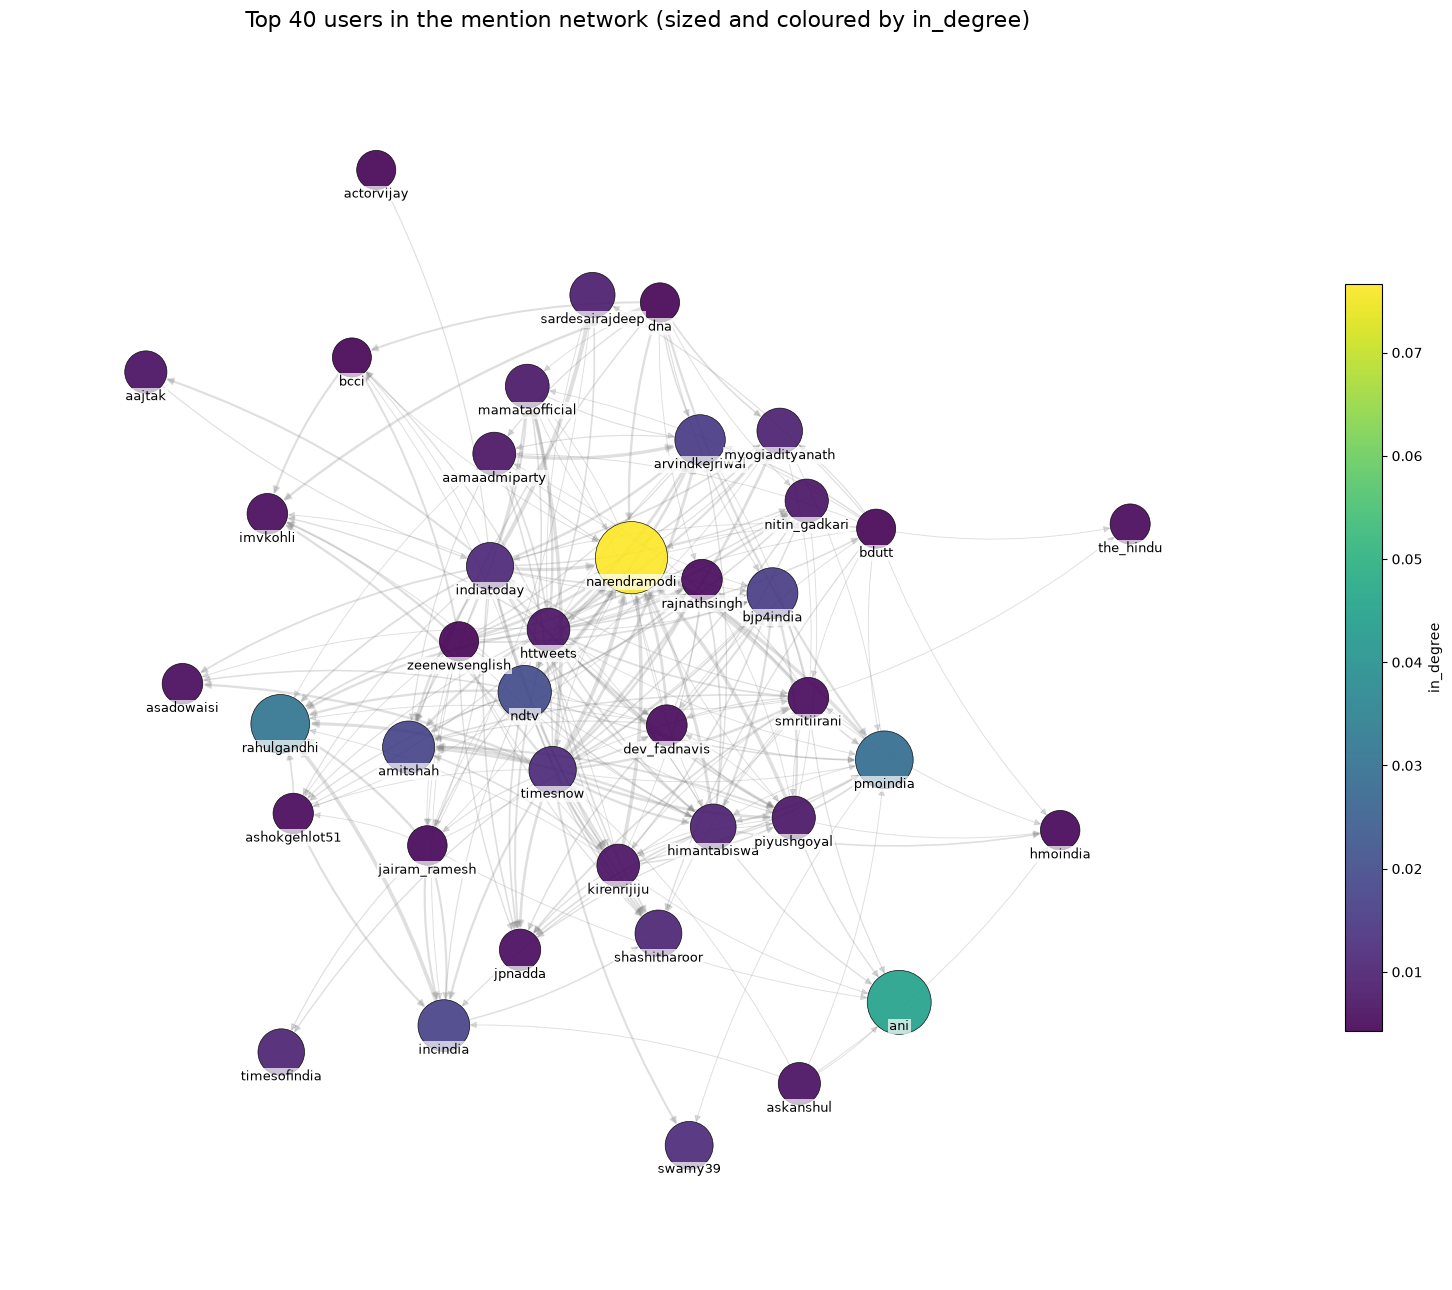

In [44]:
draw_top_network('in_degree', filename='network_in_degree.svg')

For betweenness, the top users are picked by betweenness, so the picture shows the *bridge* accounts instead.

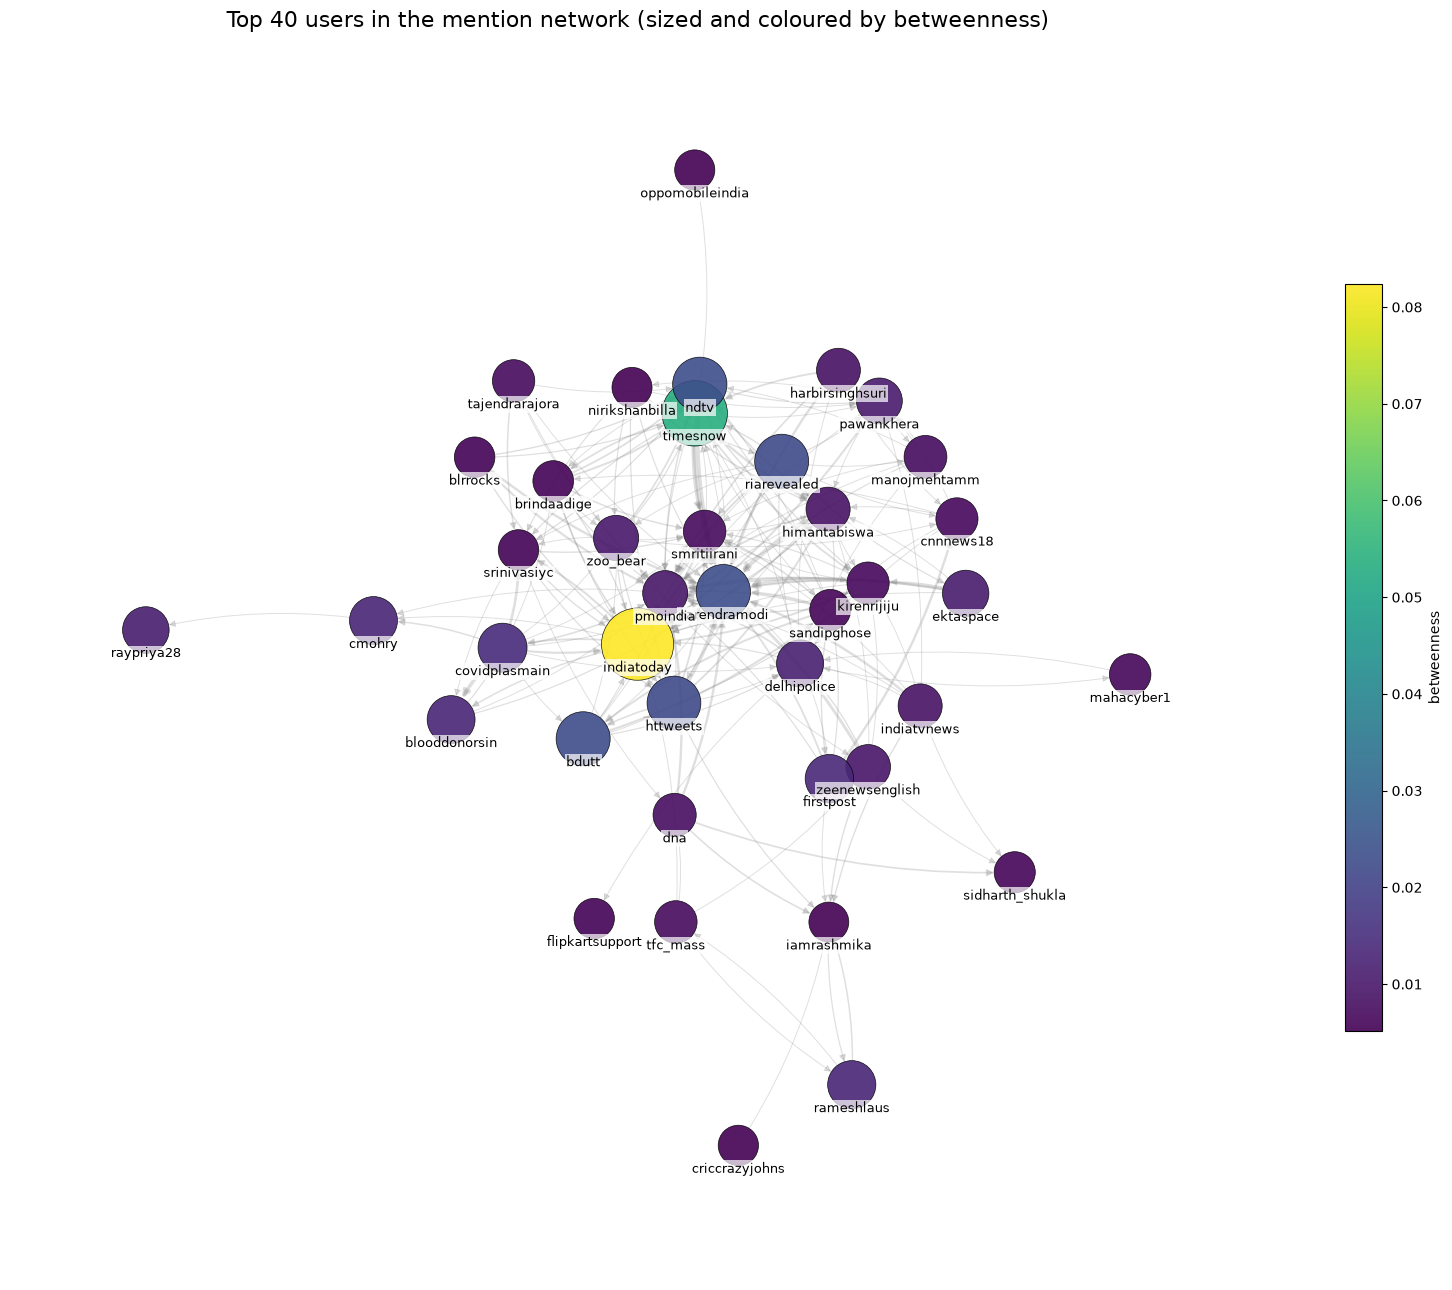

In [45]:
draw_top_network('betweenness', filename='network_betweenness.svg')